# 02 · Data quality

Before trusting any test result, check that the experiments were run correctly.

In [7]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import upworthy as uw

pd.set_option("display.max_columns", None)
uw.FIG_DIR.mkdir(parents=True, exist_ok=True)

con = uw.connect()

## 1. Test inventory

In [8]:
tests = con.execute("SELECT * FROM tests").df()
tests["is_aa"] = tests["is_aa"].astype(bool)
tests["in_problem_period"] = tests["in_problem_period"].astype(bool)

print(f"Tests: {len(tests):,}")
print(f"Date range: {tests['test_start'].min()} to {tests['test_start'].max()}")
tests[["n_arms", "impressions", "clicks", "ctr_pooled"]].describe().round(4)

Tests: 4,873
Date range: 2013-01-26 20:10:36 to 2015-04-29 22:44:51.741000


,n_arms,impressions,clicks,ctr_pooled
count,4873.0000,4873.0000,4873.0000,4873.0000
mean,4.6513,16627.1601,252.6591,0.0163
std,1.1858,7750.0668,199.6524,0.0121
min,2.0000,86.0000,0.0000,0.0000
25%,4.0000,11268.0000,123.0000,0.0081
50%,4.0000,14431.0000,201.0000,0.0131
75%,5.0000,19804.0000,319.0000,0.0205
max,14.0000,76900.0000,2844.0000,0.1244


In [9]:
def test_type(row):
    if row["is_aa"]:
        return "A/A (identical arms)"
    if row["n_headlines"] > 1 and row["n_images"] == 1:
        return "headline only"
    if row["n_headlines"] == 1 and row["n_images"] > 1:
        return "image only"
    return "headline + image"

tests["test_type"] = tests.apply(test_type, axis=1)
type_counts = tests["test_type"].value_counts().to_frame("n_tests")
type_counts["share"] = (type_counts["n_tests"] / len(tests)).round(3)
type_counts

,n_tests,share
test_type,,
headline only,2307,0.473
image only,1426,0.293
A/A (identical arms),840,0.172
headline + image,300,0.062


## 2. Sample ratio mismatch (SRM)

Arms in a test should get roughly equal impressions. A chi-square goodness-of-fit test checks this; p < 0.001 flags a broken split.

In [10]:
arms_all = uw.load_arms(con, include_problem_period=True)

srm = (
    arms_all.groupby("test_id")
    .agg(srm_p=("impressions", uw.srm_pvalue),
         in_problem_period=("in_problem_period", "first"))
    .reset_index()
)
srm["srm_fail"] = srm["srm_p"] < 0.001

srm.groupby("in_problem_period")["srm_fail"].agg(["count", "mean"]).rename(
    columns={"count": "n_tests", "mean": "share_failing_srm"}
).round(3)

,n_tests,share_failing_srm
in_problem_period,,
False,3822,0.005
True,1050,0.700


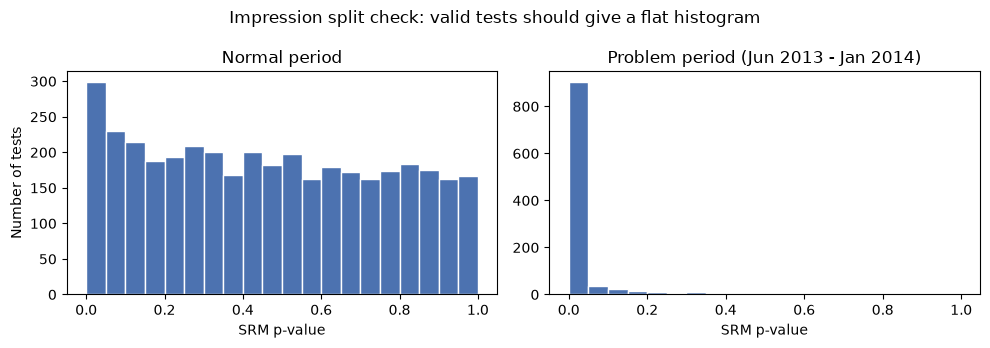

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=False)
for ax, (flag, label) in zip(axes, [(False, "Normal period"), (True, "Problem period (Jun 2013 - Jan 2014)")]):
    ax.hist(srm.loc[srm["in_problem_period"] == flag, "srm_p"], bins=20, color="#4C72B0", edgecolor="white")
    ax.set_title(label)
    ax.set_xlabel("SRM p-value")
axes[0].set_ylabel("Number of tests")
fig.suptitle("Impression split check: valid tests should give a flat histogram")
fig.tight_layout()
fig.savefig(uw.FIG_DIR / "srm_by_period.png", dpi=150)
plt.show()

**Finding.** In the documented problem period most tests fail the SRM check, while in the rest of the data almost none do.
All later analysis drops the problem period (`uw.load_arms` does this by default).

## 3. Clean sample used from here on

In [12]:
arms = uw.load_arms(con)
clean_tests = arms.groupby("test_id").agg(is_aa=("is_aa", "first"), n_arms=("n_arms", "first"))

print(f"Tests kept: {len(clean_tests):,}  (A/A: {clean_tests['is_aa'].sum():,})")
print(f"Arms kept:  {len(arms):,}")
print(f"Pooled CTR: {arms['clicks'].sum() / arms['impressions'].sum():.4f}")

Tests kept: 3,822  (A/A: 646)
Arms kept:  18,384
Pooled CTR: 0.0131
